# A* pour plusieurs robot (sans tâche)

On utilise les classes existantes pour généraliser à un ensemble de robot qu'on affecte à une pièce.

In [165]:
# import de module

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd
import networkx as nx
import tkinter as tk
import random
import math



### Classe Mur

In [166]:
class Mur:
    """ 
    Classe pour les murs de la pièce    
    """

    def __init__(self, position):
        """ 
        Paramètre:
        ----------
        position : liste de deux listes
            position des deux extrémités du mur
        """
        self.position = position
        self.longueur = np.sqrt(
            (position[1][0] - position[0][0])**2 + (position[1][1] - position[0][1])**2)
        self.type = "mur"

    def __repr__(self):
        return f"Mur de longueur {self.longueur} et de position {self.position}"

    def __str__(self):
        return f"{self.type} de longueur {self.longueur} et de position {self.position}"


print("Test de la classe Mur")
mur1 = Mur([[0, 0], [0, 1]])
print(mur1)

Test de la classe Mur
mur de longueur 1.0 et de position [[0, 0], [0, 1]]


### Classe Porte

In [167]:
# On créé une classe pour les portes de la pièce

class Porte:
    """
    Classe pour les portes de la pièce
    """

    def __init__(self, position, statut):
        """
        Constructeur de la classe
        Paramètres:
        -----------
        positon: position de la porte définis comme une liste des coordonnées de début et de fin (cf. murs)
        exemple : position = [[0,0], [0,1]]
        statut: ouvert ou fermé
        """

        self.position = position
        self.statut = statut
        self.largeur = np.sqrt(
            (position[1][0] - position[0][0])**2 + (position[1][1] - position[0][1])**2)
        self.type = "porte"

    def __str__(self):
        """
        Méthode pour afficher les informations de la porte
        :return: les informations de la porte
        """
        return f"Porte à la position {self.position} de largeur {self.largeur} et de statut {self.statut}"

    def __repr__(self):
        """
        Méthode pour afficher les informations de la porte
        :return: les informations de la porte
        """
        return f"Porte à la position {self.position} de largeur {self.largeur} et de statut {self.statut}"

    def ouvrir(self):
        """
        Méthode pour ouvrir la porte
        Ne retourne rien
        """
        self.statut = "ouverte"

    def fermer(self):
        """ 
        Méthode pour fermer la porte
        Ne retourne rien
        """
        self.statut = "fermee"


print("Test de la classe Porte")
porte1 = Porte([[0, 0], [0, 1]], "fermee")
print(porte1)

Test de la classe Porte
Porte à la position [[0, 0], [0, 1]] de largeur 1.0 et de statut fermee


### Classe Pièce

In [168]:
# On créer une pièce pour que le robot cicule dedans

class Piece:
    """
    Une pièce est définie par sa longueur, sa largeur et la liste des murs interne qui la compose.
    C'est par defaut un rectangle de longueur et largeur donnée.
    Les murs sont des segments de droite, définis par deux points en coordonnées cartésiennes
    """

    def __init__(self, longueur, largeur, liste_murs, liste_portes):
        '''
        Parameters :
        longueur : longueur de la pièce
        largeur : largeur de la pièce
        liste_murs : liste des murs de la pièce, sous la forme d'une liste de classe mur
        listes_portes : liste de portes de la pièce, sous la forme d'une liste de classe porte
        depart : coordonnées du point de départ du robot    
        arrivee : coordonnées du point d'arrivée du robot
        '''

        self.longueur = longueur
        self.largeur = largeur

        self.liste_murs = liste_murs  # sans les murs extérieurs, ni les portes fermées
        liste_position = [[[0, 0], [0, largeur]], [[0, largeur], [longueur, largeur]], [
            [longueur, largeur], [longueur, 0]], [[longueur, 0], [0, 0]]]
        self.murs_exterieurs = [Mur(position) for position in liste_position]

        self.liste_portes = liste_portes
        self.portes_ouvertes = [
            portes for portes in liste_portes if portes.statut == "ouverte"]
        self.portes_fermees = [
            portes for portes in liste_portes if portes.statut == "fermee"]

        # A modifier en introduisant une classe robot
        self.liste_robot = []
        self.robot_size = {}
        self.depart = []
        self.arrivee = []
        self.robot_associe = False

    def __repr__(self):
        if self.robot_associe:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, contenant le robot {self.robot.nom} "
        else:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, sans robot associé"

    def __str__(self):
        if self.robot_associe:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, contenant le robot {self.robot.nom} "
        else:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, sans robot associé"

    def associer_robot(self, robot):
        """
        Associe des robot à la pièce
        Paramètres:
        robot: robot à associer
        """
        self.liste_robot.append(robot)
        self.robot_associe = True

        # on dimentionne le parcours pour le plus gros robot. Là où il passe, tous les autres passent
        self.robot_size[robot] = robot.taille

        self.depart.append(robot.position)

    def afficher(self, plot_grille=True, grid_size=2, plot_accessible=False, plot_path=True):
        """
        Affiche la pièce
        """
    
        # On plot les mur et les portes fermées
        list_plot = [self.murs_exterieurs,
                    self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]

        plt.figure(figsize=(10, 10))
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot([position[0][0], position[1][0]], [position[0][1], position[1][1]], color=liste_couleur[i],
                        linewidth=liste_largeur[i])

        # On plot la grille
        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue',
                                marker='+', s=50, linewidth=1)

        # On plot le chemin trouvé
        demarage = self.depart

        if plot_path:
            colors = ['green', 'blue', 'red']

            for i in range(len(self.liste_robot)):
                # on trace le chemin pour chacun des robots
                robot = self.liste_robot[i]
                depart = demarage[i]
                pathes, etapes = self.plus_court_chemin_tsp(
                    depart, grid_size, robot)
                # on génère une liste de couleurs pour les étapes

                couleur = colors[i]
                for j in range(len(etapes)):
                    plt.plot([p[0] for p in pathes[j]], [p[1]
                            for p in pathes[j]], color=couleur, linewidth=4)
                    plt.scatter(etapes[j][0], etapes[j][1],
                                color=couleur, marker='o', s=50, linewidth=4)
                    plt.text(etapes[j][0], etapes[j][1],
                            etapes[j][2], fontsize=12)

                plt.scatter(demarage[i][0], demarage[i][1], color='black',
                            marker='^', s=70, linewidth=4, label=f"Départ {robot.nom}")
        plt.title("TECHLAB")
        plt.legend()
        plt.axis('equal')
        plt.show()


    def grille(self, grid_size):
        """
        Renvoie la grille de la pièce
        Paramètres:
        grid_size: ecart entre deux points de la grille

        :return: x_grille, y_grille: coordonnées des points de la grille (listes de même taille)
        """

        # on crée une liste de points espacés de grid_size
        x_grille = np.arange(0, self.longueur + 1, grid_size)
        y_grille = np.arange(0, self.largeur + 1, grid_size)

        return x_grille, y_grille

    def coord_mur(self):
        """
        Renvoie les coordonnées des murs de la pièce sous la forme de deux listes
        """
        x_wall = []
        y_wall = []
        liste_murs = self.murs_exterieurs + self.liste_murs + self.portes_fermees
        for mur in liste_murs:
            x_wall.append([mur.position[0][0], mur.position[1][0]])
            y_wall.append([mur.position[0][1], mur.position[1][1]])

        return x_wall, y_wall

    def is_in_wall(self, x_test, y_test, robot_size, do_plot=True):
        """
        Renvoie True si le point (x_test, y_test) est à une distance inférieure à une marge (eg. robot_size) d'un mur, le robot est un cercle de rayon robot_size
        Paramètres:
        x_test, y: coordonnées du point à tester
        robot_size: rayon du robot

        """
        x_wall, y_wall = self.coord_mur()
        nb_murs = len(x_wall)

        for i in range(0, nb_murs):
            # On ne connait pas le mur de facon continue, on le connait par ses points extrêmes
            # on calcule le projeté orthogonal du point sur le mur
            wall = [[x_wall[i][0], y_wall[i][0]], [x_wall[i][1], y_wall[i][1]]]

            vecteur_mur = [wall[1][0]-wall[0][0], wall[1][1]-wall[0][1]]

            vecteur_point_robot = [x_test - wall[0][0], y_test - wall[0][1]]

            projete = np.dot(vecteur_point_robot, vecteur_mur) / \
                np.dot(vecteur_mur, vecteur_mur)
            point_projete = [wall[0][0]+projete*vecteur_mur[0],
                             wall[0][1] + projete*vecteur_mur[1]]

            # on verifie que le point projeté est bien sur le segment
            if point_projete[0] < min(wall[0][0], wall[1][0]) or point_projete[0] > max(wall[0][0], wall[1][0]):
                continue
            if point_projete[1] < min(wall[0][1], wall[1][1]) or point_projete[1] > max(wall[0][1], wall[1][1]):
                continue

            # sur le mur, forme avec le centre du robot un vecteur normal au mur
            dist_projete = np.sqrt(
                (x_test-point_projete[0])**2 + (y_test-point_projete[1])**2)
            if do_plot:
                # on veut que le robot soit à l'echelle sur le plot
                # cf. https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.scatter.html
                s = 172*robot_size
                plt.scatter(x_test, y_test, color='green',
                            marker='o', s=s, linewidth=4)
                plt.scatter(point_projete[0], point_projete[1],
                            color='red', marker='o', s=50, linewidth=2)
                plt.plot([wall[0][0], wall[1][0]], [wall[0][1],
                         wall[1][1]], color='black', linewidth=2)
            
            if dist_projete < robot_size:
                return True

        return False
    
    def bresenham_line(self, p1, p2):
        """
        Implémente l'algorithme de Bresenham pour tracer une ligne entre p1 et p2.
        Retourne une liste de points (x, y) représentant la ligne.

        p1, p2 : tuples (x, y) représentant les coordonnées des points de début et de fin.
        """
        x1, y1 = p1
        x2, y2 = p2
        points = []

        dx = abs(x2 - x1)
        dy = abs(y2 - y1)
        sx = 1 if x1 < x2 else -1
        sy = 1 if y1 < y2 else -1
        err = dx - dy

        while True:
            points.append((x1, y1))
            if x1 == x2 and y1 == y2:
                break
            e2 = 2 * err
            if e2 > -dy:
                err -= dy
                x1 += sx
            if e2 < dx:
                err += dx
                y1 += sy

        return points

    def seg_coupe_obstacle(self, p1, p2):
        """
        Vérifie si le segment [p1, p2] traverse un mur ou une porte fermée.
        Retourne True si le segment coupe un obstacle, sinon False.
        
        p1, p2 : points définissant le segment (tuples (x, y))
        """
        # Utiliser murs_exterieurs, liste_murs et portes_fermees comme obstacles
        obstacles = self.murs_exterieurs + self.liste_murs + self.portes_fermees
        
        for obs in range(len(obstacles)):
            # Coordonnées du segment obstacle
            (x1, y1), (x2, y2) = obstacles[obs].position
            mur_points = self.bresenham_line((x1, y1), (x2, y2))
                    
            # Vérifier si la ligne entre p1 et p2 passe par un point du mur
            for point in self.bresenham_line(p1, p2):
                if point in mur_points:
                    
                    return True  # Il y a une collision

        return False  # Aucun obstacle traversé
    

    def accessible(self, grid_size, robot):
        """
        Renvoie True si le point (x_test, y_test) est accessible, c'est à dire si il n'est pas trop proche un mur,
        ou dans une porte fermée
        Paramètres:
        x_test, y: coordonnées du point à tester
        robot_size: rayon du robot
        doplot: si True, affiche les point accessibles en orange
        """
        robot_size = self.robot_size[robot]
        x_grid, y_grid = self.grille(grid_size)

        accessible = []

        for i in range(len(x_grid)):
            for j in range(len(y_grid)):
                if not self.is_in_wall(x_grid[i], y_grid[j], robot_size, do_plot=False):
                    accessible.append((x_grid[i], y_grid[j]))

        return accessible

    def get_graphe(self, grid_size, robot):
        """
        Renvoie le graphe (liste d'ajacence) de la pièce, c'est à dire la grille de la pièce moins les points non accessibles
        Paramètres:
        grid_size: ecart entre deux points de la grille
        robot_size: rayon du robot
        doplot: si True, affiche le graphe

        """

        # on initialise le graphe comme un dictionnaire
        accessible = self.accessible(grid_size, robot)
        graphe = {}
        max_distance = grid_size * 3

        for i in range(len(accessible)):
            # pour tout sommet accessible, on cherche les plus proche voisins
            graphe[accessible[i]] = []
            for j in range(len(accessible)):
                if i == j:
                    continue
                dist = np.sqrt(
                    (accessible[i][0]-accessible[j][0])**2 + (accessible[i][1]-accessible[j][1])**2)
                # on ne relie que les points proches (diagonalement aussi)
                if dist <= max_distance and not self.seg_coupe_obstacle(accessible[i], accessible[j]):
                    # on verifie que le segment ne passe pas par un mur / une porte fermée

                    graphe[accessible[i]].append(accessible[j])

        return graphe

    def plus_court_chemin_tsp(self, depart, grid_size, robot, k=1):
        ''' 
        Fonction qui utilise le TSP pour trouver le chemin optimal entre toutes les tâches.
        Paramètres:
        depart: coordonnées du point de départ (sous la forme d'une liste)
        grid_size: écart entre deux points de la grille
        robot: objet représentant le robot
        k: facteur d'échelle
        '''
        g = self.get_graphe(grid_size, robot)

        graphe = nx.Graph(g)

        # Étape 1 : Construire la liste des lieux (tâches) à visiter
        liste_lieux = [(depart[0] * k, depart[1] * k)]  # Inclut le point de départ
        for tache in robot.taches:
            lieux = [[l[0] * k, l[1] * k] for l in tache.liste_lieux]
            liste_lieux += lieux

        # Étape 2 : Créer un graphe complet pour le TSP
        tsp_graph = nx.complete_graph(len(liste_lieux))
        positions = {i: tuple(liste_lieux[i]) for i in range(len(liste_lieux))}

        # Calculer les poids des arêtes (distances euclidiennes)
        for i in tsp_graph.nodes():
            for j in tsp_graph.nodes():
                if i != j:
                    try:
                        tsp_graph.edges[i, j]['weight'] = nx.shortest_path_length(graphe, positions[i], positions[j], weight="weight")
                    except nx.NetworkXNoPath:
                        tsp_graph.edges[i, j]['weight'] = float('inf')  # Penaliza caminhos impossíveis

        # Étape 3 : Trouver le chemin optimal avec le TSP
        tsp_cycle = nx.approximation.traveling_salesman_problem(
            tsp_graph, weight="weight", cycle=True
        )

        # Étape 4 : Convertir les indices du TSP en coordonnées réelles
        pathes = []
        etapes = []
        for i in range(len(tsp_cycle) - 1):
            start_idx = tsp_cycle[i]
            end_idx = tsp_cycle[i + 1]
            start = positions[start_idx]
            end = positions[end_idx]
            etapes.append([end[0], end[1], f"Tâche {i}"])
            try:
                pathes.append(nx.astar_path(graphe, start, end, weight="weight"))
            except nx.NetworkXNoPath:
                raise ValueError("Il n'y a pas de chemin entre le point de départ et le point d'arrivée")

        return pathes, etapes
    
    def plus_court_chemin_tsp_otimise(self, depart, graphe, grid_size, robot, k=1):
        ''' 
        Fonction qui utilise le TSP pour trouver le chemin optimal entre toutes les tâches.
        Cette function est utilisé seulement pour trouver le meiller point de depart
        Paramètres :
        - depart : coordonnées du point de départ.
        - graphe : graphe déjà construit pour éviter de le recalculer.
        - grid_size : écart entre deux points de la grille.
        - robot : objet représentant le robot.
        - k : facteur d'échelle.

        Retourne :
        - pathes : Liste des chemins optimaux.
        - etapes : Liste des étapes du chemin.
        - distance_totale : Somme des longueurs des chemins.
        '''

        # Étape 1 : Construire la liste des lieux (tâches) à visiter
        liste_lieux = [(depart[0] * k, depart[1] * k)]  # Inclut le point de départ
        for tache in robot.taches:
            lieux = [[l[0] * k, l[1] * k] for l in tache.liste_lieux]
            liste_lieux += lieux

        # Étape 2 : Créer un graphe complet pour le TSP
        tsp_graph = nx.complete_graph(len(liste_lieux))
        positions = {i: tuple(liste_lieux[i]) for i in range(len(liste_lieux))}

        # Calculer les poids des arêtes (distances euclidiennes)
        for i in tsp_graph.nodes():
            for j in tsp_graph.nodes():
                if i != j:
                    try:
                        tsp_graph.edges[i, j]['weight'] = nx.shortest_path_length(graphe, positions[i], positions[j], weight="weight")
                    except nx.NetworkXNoPath:
                        tsp_graph.edges[i, j]['weight'] = float('inf')  # Penaliza caminhos impossíveis

        # Étape 3 : Trouver le chemin optimal avec le TSP
        tsp_cycle = nx.approximation.traveling_salesman_problem(
            tsp_graph, weight="weight", cycle=True
        )

        # Étape 4 : Convertir les indices du TSP en coordonnées réelles
        pathes = []
        etapes = []
        distance_totale = 0

        for i in range(len(tsp_cycle) - 1):
            start_idx = tsp_cycle[i]
            end_idx = tsp_cycle[i + 1]
            start = positions[start_idx]
            end = positions[end_idx]
            etapes.append([end[0], end[1], f"Tâche {i}"])

            try:
                chemin = nx.astar_path(graphe, start, end, weight="weight")
                pathes.append(chemin)
                distance_totale += len(chemin)
            except nx.NetworkXNoPath:
                raise ValueError("Il n'y a pas de chemin entre le point de départ et le point d'arrivée")

        return pathes, etapes, distance_totale
    
    def plus_court_chemin_tsp_avec_energie(self, depart, robot, grid_size):
        """
        Version modifiée de plus_court_chemin_tsp avec gestion de l'énergie
        Paramètres:
        - depart : point de départ [x, y]
        - robot : instance de la classe Robot
        - grid_size : taille de la grille
        Retourne:
        - pathes : liste des chemins optimaux
        - etapes : liste des étapes avec coordonnées
        - distance_totale : distance totale parcourue
        """
        # 1. Récupération du graphe
        g = self.get_graphe(grid_size, robot)
        graphe = nx.Graph(g)

        # 2. Construction des lieux à visiter (départ + tâches)
        liste_lieux = [(depart[0], depart[1])]  # Point de départ
        for tache in robot.taches:
            liste_lieux.extend([(lieu[0], lieu[1]) for lieu in tache.liste_lieux])

        # 3. Création du graphe complet pour TSP
        tsp_graph = nx.complete_graph(len(liste_lieux))
        positions = {i: lieu for i, lieu in enumerate(liste_lieux)}

        # Calcul des poids (distances avec obstacles)
        for i in tsp_graph.nodes():
            for j in tsp_graph.nodes():
                if i != j:
                    try:
                        tsp_graph.edges[i,j]['weight'] = nx.shortest_path_length(
                            graphe, positions[i], positions[j], weight="weight")
                    except nx.NetworkXNoPath:
                        tsp_graph.edges[i,j]['weight'] = float('inf')

        # 4. Résolution TSP
        try:
            tsp_cycle = nx.approximation.traveling_salesman_problem(
                tsp_graph, cycle=True, weight="weight")
        except nx.NetworkXError:
            raise ValueError("Aucun chemin TSP valide trouvé")

        # 5. Construction des chemins avec contrôle énergétique
        pathes = []
        etapes = []
        distance_totale = 0
        energie_depensee = 0

        for i in range(len(tsp_cycle) - 1):
            start_idx = tsp_cycle[i]
            end_idx = tsp_cycle[i+1]
            start = positions[start_idx]
            end = positions[end_idx]

            # Calcul du chemin A* réel
            try:
                chemin = nx.astar_path(graphe, start, end)
                distance = len(chemin) * grid_size
            except nx.NetworkXNoPath:
                continue

            # Vérification énergie (uniquement pour les tâches, pas le départ)
            if i > 0:  # Les tâches commencent à l'index 1 (0 = départ)
                tache = self._trouver_tache_par_position(end, robot)
                if tache:
                    cout_total = (distance * robot.cout_deplacement_par_unite) + tache.energie_requise
                    
                    if cout_total > robot.energie_restante:
                        print(f"Robot {robot.nom}: énergie insuffisante pour {tache.nom}")
                        robot.recharger()  # Ou return None pour replanification
                        return None
                    
                    robot.consommer_energie(distance, tache.energie_requise)

            pathes.append(chemin)
            etapes.append([end[0], end[1], f"Étape {i}"])
            distance_totale += distance

        return pathes, etapes, distance_totale

    def _trouver_tache_par_position(self, position, robot):
        """Helper pour trouver une tâche par sa position"""
        for tache in robot.taches:
            if (position[0], position[1]) in [(lieu[0], lieu[1]) for lieu in tache.liste_lieux]:
                return tache
        return None


    def maj_porte(self):
        """
        Modifie la liste des murs et des portes fermées en fonction des portes ouvertes ou fermées
        Si une porte est fermée, on l'ajoute à la liste des murs (comme un nouveau mur) et on l'enlève de la liste des portes
        Si une porte est ouverte, on l'ajoute à la liste des portes ouvertes et on l'enlève de la liste des murs
        """

        liste_portes = self.liste_portes

        new_porte_fermee = []
        new_porte_ouverte = []
        for porte in liste_portes:
            if porte.statut == "ouverte":
                new_porte_ouverte.append(porte)
            else:  # porte.statut == "fermee"
                new_porte_fermee.append(porte)

        self.portes_ouvertes = new_porte_ouverte
        self.portes_fermees = new_porte_fermee


## Classe Tâche

On appel tâche un lieu (coordonnées) et une action (chaîne de caractère) à laquelle on associe une [fonction]

Liste d'action : 

    - Surveiller [Surveillance]

    - Ouvrir porte [Bras]

    - Fermer porte [Bras]

    - Recuperer Objet [Manutention]

    - Déposer Objet [Manutention]


*Hypothèse* - Un robot n'a qu'une fonction, et ne peux donc executer qu'un type d'action

In [169]:
import pandas as pd

class Tache:
    def __init__(self, nom, liste_lieux, liste_action, energie_requise_taches, prerequis=None, duree=0):
        ''' 
        Une tâche est définie par :
        - nom : nom de la tâche
        - liste_lieux : liste des lieux à visiter (coordonnées)
        - liste_action : actions à effectuer (dans l'ordre)
        - energie_requise_taches : énergie nécessaire (liste ou valeur unique)
        - prerequis : tâche prérequise (optionnel)
        - duree : durée totale (optionnel)
        '''
        # Validation des entrées
        if not isinstance(liste_lieux, list) or not all(isinstance(coord, (list, tuple)) for coord in liste_lieux):
            raise ValueError("liste_lieux doit être une liste de coordonnées")
        if len(liste_lieux) != len(liste_action):
            raise ValueError("liste_lieux et liste_action doivent avoir la même longueur")
        
        self.nom = nom
        self.liste_lieux = liste_lieux
        self.liste_action = liste_action
        self.prerequis = prerequis
        self.duree = duree
        
        # Validation et normalisation de l'énergie
        if isinstance(energie_requise_taches, (int, float)):
            self.energie_requise_taches = [float(energie_requise_taches)] * len(liste_lieux)
        elif isinstance(energie_requise_taches, list):
            if len(energie_requise_taches) != len(liste_lieux):
                raise ValueError("energie_requise_taches doit avoir la même longueur que liste_lieux")
            self.energie_requise_taches = [float(e) for e in energie_requise_taches]
        else:
            raise TypeError("energie_requise_taches doit être un nombre ou une liste de nombres")

        # Création du DataFrame
        self.df = pd.DataFrame({
            "ordre": range(len(liste_lieux)),
            "lieu": liste_lieux,
            "action": liste_action,
            "energie_requise": self.energie_requise_taches
        }).set_index("ordre")

    def __str__(self):
        energie_totale = sum(self.energie_requise_taches)
        return f"[Tâche] {self.nom} (Étapes: {len(self.liste_lieux)}, Énergie totale: {energie_totale})"

    def __repr__(self):
        return f"Tache(nom={self.nom!r}, lieux={self.liste_lieux}, actions={self.liste_action})"

    def get_lieu(self, ordre):
        """Renvoie le lieu à l'ordre donné avec vérification."""
        try:
            return self.liste_lieux[ordre]
        except IndexError:
            raise IndexError(f"Ordre {ordre} invalide. Maximum: {len(self.liste_lieux)-1}")

    def get_action(self, ordre):
        """Renvoie l'action à l'ordre donné avec vérification."""
        try:
            return self.liste_action[ordre]
        except IndexError:
            raise IndexError(f"Ordre {ordre} invalide. Maximum: {len(self.liste_action)-1}")

    def get_energie_etape(self, ordre=None):
        """Renvoie l'énergie requise pour une étape ou la liste complète."""
        if ordre is not None:
            try:
                return self.energie_requise_taches[ordre]
            except IndexError:
                raise IndexError(f"Ordre {ordre} invalide. Maximum: {len(self.energie_requise_taches)-1}")
        return self.energie_requise_taches.copy()


class EmptyTache:
    """Classe pour une tâche vide (patron Null Object)."""
    def __init__(self):
        self.nom = "empty"
        self.liste_lieux = []
        self.liste_action = []
        self.energie_requise_taches = []
        self.df = pd.DataFrame({"ordre": [], "lieu": [], "action": [], "energie_requise": []}).set_index("ordre")

    def __str__(self):
        return "[Tâche vide]"

    def __repr__(self):
        return "EmptyTache()"

    def get_lieu(self, ordre):
        raise IndexError("Aucun lieu disponible (tâche vide)")

    def get_action(self, ordre):
        raise IndexError("Aucune action disponible (tâche vide)")

    def get_energie_etape(self, ordre=None):
        return 0 if ordre is not None else []


# Exemple d'utilisation
try:
    task = Tache(
        nom="task1",
        liste_lieux=[[4, 12], [60, 34]],
        liste_action=["start", "surveiller"],
        energie_requise_taches=[10, 5],  # Liste d'énergies
        prerequis="None"
    )
    print(task)
    print(task.df)
    print("Énergie étape 1:", task.get_energie_etape(1))
    
    task2 = EmptyTache()
    print(task2)

except Exception as e:
    print(f"Erreur: {e}")

[Tâche] task1 (Étapes: 2, Énergie totale: 15.0)
           lieu      action  energie_requise
ordre                                       
0       [4, 12]       start             10.0
1      [60, 34]  surveiller              5.0
Énergie étape 1: 5.0
[Tâche vide]


## Classe Robot

In [170]:
class Robot:
    """ 
    Classe pour le robot
    """

    def __init__(self, position, taille, nom, fonction=None, taches=None, energie_max=100, energie_restante=None, cout_deplacement=1.0):
        """
        Constructeur de la classe
        Paramètres:
        -----------
        position: position du robot définie comme une liste des coordonnées
        taille: taille du robot (rayon du cercle)
        nom: nom du robot
        fonction: fonction du robot (patrol, clean, etc.)
        taches: liste des tâches du robot (objets Tache)
        energie_max: énergie maximale du robot (défaut = 100)
        energie_restante: énergie actuelle (par défaut égale à energie_max)
        cout_deplacement: coût énergétique par unité de distance
        """
        self.position = position
        self.taille = taille
        self.nom = nom
        self.taches = taches if taches is not None else []
        self.current_tache = 0  # indice de la tâche en cours
        self.current_lieu = 0   # indice du lieu en cours
        self.fonction = fonction
        self.energie_max = energie_max
        self.energie_restante = energie_max if energie_restante is None else energie_restante
        self.cout_deplacement_par_unite = cout_deplacement

    def __str__(self):
        return f"[Robot] {self.nom} (Énergie: {self.energie_restante}/{self.energie_max})"

    def __repr__(self):
        return f"Robot(nom={self.nom}, position={self.position})"

    def deplacer(self, position):
        """
        Déplace le robot à une nouvelle position
        Ne vérifie pas les collisions pour l'instant
        """
        self.position = position

    def effectuer_tache(self):
        """
        Effectue la tâche en cours et consomme l'énergie nécessaire
        Si l'énergie est insuffisante, recharge automatiquement le robot
        """
        if self.current_tache >= len(self.taches):
            print("Aucune tâche à effectuer")
            return False

        tache = self.taches[self.current_tache]
        energie_requise = sum(tache.get_energie_etape())

        if self.energie_restante >= energie_requise:
            print(f"Robot {self.nom} effectue {tache.nom}")
            self.energie_restante -= energie_requise
            self.current_tache += 1
            return True
        else:
            print(f"Energie insuffisante pour {tache.nom} (nécessite {energie_requise} unités, disponible: {self.energie_restante}/{self.energie_max})")
            print(f"-> Recharge automatique de {self.nom}...")
            self.reset_energie()  # Recharge à energie_max (100 par défaut)
            print(f"-> {self.nom} rechargé ({self.energie_max} unités disponibles)")
            
            # Nouvelle tentative après recharge
            if self.energie_restante >= energie_requise:
                print(f"Robot {self.nom} effectue {tache.nom} après recharge")
                self.energie_restante -= energie_requise
                self.current_tache += 1
                return True
            else:
                print(f"Erreur: Energie toujours insuffisante après recharge")
                return False

    def meet_prerequis(self, tache):
        """
        Vérifie si le robot peut effectuer la tâche (prérequis)
        """
        if tache.prerequis is None or tache.prerequis == "None":
            return True
        return tache.prerequis == self.fonction

    def clear_taches(self):
        """Réinitialise la liste des tâches"""
        self.taches = []
        self.current_tache = 0

    def sumup_robot(self):
        """Affiche le récapitulatif du robot"""
        print("\n-----------------")
        print(f"Robot [{self.nom}]")
        print("-------")
        print("Tâches:")
        
        for i, tache in enumerate(self.taches):
            print(f"{i+1}. {tache.nom}")
            print(f"   Lieux: {tache.liste_lieux}")
            print(f"   Actions: {tache.liste_action}")
            print(f"   Energie requise: {sum(tache.get_energie_etape())}")
        
        print(f"\nQuantité de tâches: {len(self.taches)}")
        print(f"Fonction: {self.fonction}")
        print(f"Position: {self.position}")
        print(f"Taille: {self.taille}")
        print(f"Energie restante: {self.energie_restante}/{self.energie_max}")
        print("-----------------")

    def reset_position(self):
        """Réinitialise la position du robot"""
        if len(self.position) > 0:
            self.position = [self.position[0]]
            self.current_lieu = 0

    def reset_energie(self, energie_max=None):
        """Réinitialise l'énergie du robot à sa valeur maximale (100 par défaut)"""
        if energie_max is not None:
            self.energie_max = energie_max
        self.energie_restante = self.energie_max


# Exemple d'utilisation avec energie_max=100
if __name__ == "__main__":
    # Création d'une tâche coûteuse
    tache1 = Tache(
        nom="nettoyage_complet",
        liste_lieux=[[0, 0], [10, 10], [20, 20]],
        liste_action=["aspirer", "laver", "sécher"],
        energie_requise_taches=[40, 30, 30],  
        prerequis="nettoyage"
    )

    # Création d'un robot avec energie_max=100 (valeur par défaut)
    robot1 = Robot(
        position=[[0, 0]],
        taille=1.5,
        nom="CleanBot",
        fonction="nettoyage",
        energie_restante=80  # Energie initiale inférieure au maximum
    )

    # Assignation de tâche
    if robot1.meet_prerequis(tache1):
        robot1.taches.append(tache1)
        print(f"\nTâche '{tache1.nom}' assignée à {robot1.nom}")
    else:
        print(f"Le robot ne peut pas effectuer cette tâche")

    # Affichage initial
    print("\n=== ÉTAT INITIAL ===")
    robot1.sumup_robot()

    # Tentative d'exécution (doit déclencher recharge)
    print("\n=== EXÉCUTION ===")
    robot1.effectuer_tache()

    # Affichage final
    print("\n=== ÉTAT FINAL ===")
    robot1.sumup_robot()


Tâche 'nettoyage_complet' assignée à CleanBot

=== ÉTAT INITIAL ===

-----------------
Robot [CleanBot]
-------
Tâches:
1. nettoyage_complet
   Lieux: [[0, 0], [10, 10], [20, 20]]
   Actions: ['aspirer', 'laver', 'sécher']
   Energie requise: 100.0

Quantité de tâches: 1
Fonction: nettoyage
Position: [[0, 0]]
Taille: 1.5
Energie restante: 80/100
-----------------

=== EXÉCUTION ===
Energie insuffisante pour nettoyage_complet (nécessite 100.0 unités, disponible: 80/100)
-> Recharge automatique de CleanBot...
-> CleanBot rechargé (100 unités disponibles)
Robot CleanBot effectue nettoyage_complet après recharge

=== ÉTAT FINAL ===

-----------------
Robot [CleanBot]
-------
Tâches:
1. nettoyage_complet
   Lieux: [[0, 0], [10, 10], [20, 20]]
   Actions: ['aspirer', 'laver', 'sécher']
   Energie requise: 100.0

Quantité de tâches: 1
Fonction: nettoyage
Position: [[0, 0]]
Taille: 1.5
Energie restante: 0.0/100
-----------------


In [ ]:
numero = dist * energiecrobot

robot.resetEnergieRestqnte(numero)

## Import des murs 

Depuis un fichier xslx qui donne les coordonnées des murs

mur de longueur 10.0 et de position [[56, 40], [56, 30]]


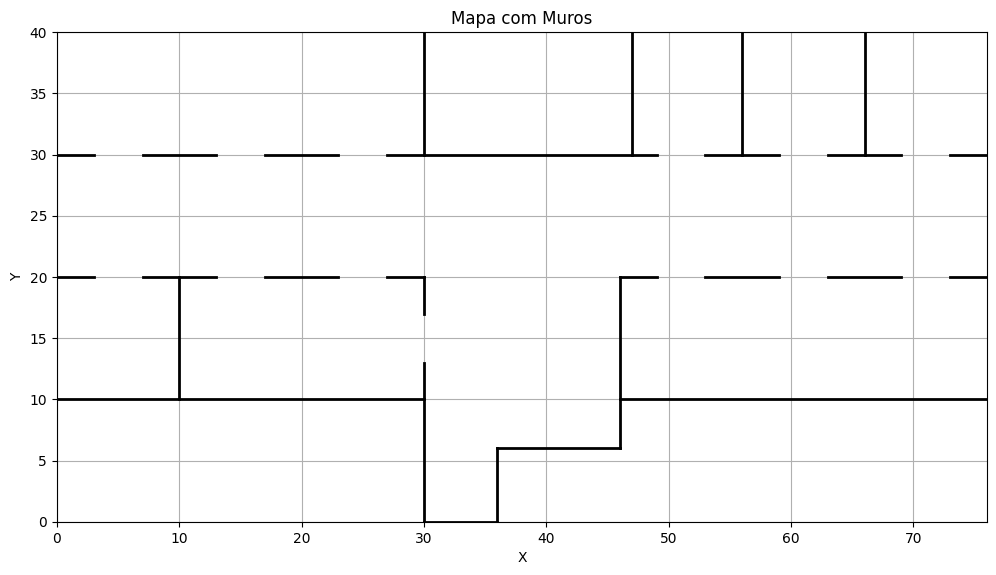

[Mur de longueur 10.0 et de position [[30, 40], [30, 30]],
 Mur de longueur 10.0 et de position [[47, 40], [47, 30]],
 Mur de longueur 10.0 et de position [[56, 40], [56, 30]],
 Mur de longueur 10.0 et de position [[66, 40], [66, 30]],
 Mur de longueur 3.0 et de position [[0, 30], [3, 30]],
 Mur de longueur 6.0 et de position [[7, 30], [13, 30]],
 Mur de longueur 6.0 et de position [[17, 30], [23, 30]],
 Mur de longueur 22.0 et de position [[27, 30], [49, 30]],
 Mur de longueur 6.0 et de position [[53, 30], [59, 30]],
 Mur de longueur 6.0 et de position [[63, 30], [69, 30]],
 Mur de longueur 3.0 et de position [[73, 30], [76, 30]],
 Mur de longueur 3.0 et de position [[0, 20], [3, 20]],
 Mur de longueur 6.0 et de position [[7, 20], [13, 20]],
 Mur de longueur 6.0 et de position [[17, 20], [23, 20]],
 Mur de longueur 3.0 et de position [[27, 20], [30, 20]],
 Mur de longueur 3.0 et de position [[46, 20], [49, 20]],
 Mur de longueur 6.0 et de position [[53, 20], [59, 20]],
 Mur de longueu

In [171]:
# import d'une disposition de murs

# FILEPATH: /C:/Mines_2A/Projet_TECHLAB/ProjectPrograms/ProjectPrograms/Astar_1robot.ipynb
# "C:\Mines_2A\Projet_TECHLAB\ProjectPrograms\ProjectPrograms\Programmes_2024\murs_techlab.xlsx"

# Lis le fichier txt
df_murs = pd.read_excel('../data/murs_techlab.xlsx', header=0)


# On créer une liste de murs
liste_murs = []
for i in range(len(df_murs)):
    position = [[df_murs.iloc[i, 0], df_murs.iloc[i, 1]],
                [df_murs.iloc[i, 2], df_murs.iloc[i, 3]]]
    liste_murs.append(Mur(position))

print(liste_murs[2])


def plot_walls(liste_murs):
    for mur in liste_murs:
        # x_inicial, x_final
        x_values = [mur.position[0][0], mur.position[1][0]]
        # y_inicial, y_final
        y_values = [mur.position[0][1], mur.position[1][1]]
        plt.plot(x_values, y_values, color='black',
                 lw=2)  # Desenha a linha do muro


# Configurar o gráfico
plt.figure(figsize=(12, 8))

# Plotar os muros
plot_walls(liste_murs)

# Ajustes para o gráfico
plt.xlim(0, 76)
plt.ylim(0, 40)
plt.gca().set_aspect('equal', adjustable='box')

# Adicionar título e rótulos
plt.title('Mapa com Muros')
plt.xlabel('X')
plt.ylabel('Y')

# Exibir o gráfico
plt.grid(True)
plt.show()
liste_murs

## Import des portes

Dans un fichier xslx qui donne les coordonnées des portes

In [173]:
# import d'une disposition de portes

# FILEPATH: /C:/Mines_2A/Projet_TECHLAB/ProjectPrograms/ProjectPrograms/Astar_1robot.ipynb
# "C:\Mines_2A\Projet_TECHLAB\ProjectPrograms\ProjectPrograms\Programmes_2024\portes_techlab.xlsx"

# Lis le fichier txt
df_portes = pd.read_excel('../data/portes_techlab.xlsx', header=0)

# On créer une liste de portes
liste_portes = []
for i in range(len(df_portes)):
    liste_portes.append(Porte([[df_portes.iloc[i, 0], df_portes.iloc[i, 1]], [
                        df_portes.iloc[i, 2], df_portes.iloc[i, 3]]], df_portes.iloc[i, 4]))

df_portes
liste_portes[8].ouvrir()
liste_portes[7].ouvrir()
liste_portes[5].ouvrir()
liste_portes[0].ouvrir()
liste_portes[4].ouvrir()
liste_portes[10].ouvrir()
liste_portes

[Porte à la position [[3, 20], [7, 20]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[3, 30], [7, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[13, 20], [17, 20]] de largeur 4.0 et de statut fermee,
 Porte à la position [[13, 30], [17, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[23, 30], [27, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[49, 30], [53, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[59, 30], [63, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[69, 30], [73, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[49, 20], [53, 20]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[59, 20], [63, 20]] de largeur 4.0 et de statut fermee,
 Porte à la position [[69, 20], [73, 20]] de largeur 4.0 et de statut ouverte]

## Algoritme A*

Exemple d'execution dans la classe. Toutes les fonctions sont appelées par la methode *afficher*.

# Exemple 

# Affectation des tâches aux robots

On importe des tâches d'un Excel et on les assignent aux robots. Pour cela on utilise des graphes.

On souhaite qu'une tâche soit construite à partir de sous-tâches (intitulé, coordonées_X, coordonnées_Y, prérequis) qui nécessite une certaine fonction d'un robot. On regroupe les sous-tâches par fonctions. 

In [174]:
# on importes des tâches depuis un fichier xslx

df_sous_taches = pd.read_excel(
    "robots_taches.xlsx", header=0, sheet_name="taches")
df_robots = pd.read_excel("../data/robots_taches.xlsx", header=0, sheet_name="robots")

df_robots

,Nom du robot,Depart_x,Depart_y,Taille,Fonction
0,SPOT,10,26,2,Bras
1,UNITREE_GO1_1,38,10,1,Camera
2,UNITREE_GO1_2,40,10,1,Camera
3,UNITREE_GO1_3,42,10,1,Camera
4,R2D2,70,26,1,Thermometre
5,R5D4,72,26,1,Thermometre


In [175]:
# création des robots

liste_robots = []
for i in range(len(df_robots)):
    liste_robots.append(
        Robot(
            position=[df_robots.iloc[i, 1], df_robots.iloc[i, 2]],
            taille=df_robots.iloc[i, 3],
            nom=df_robots.iloc[i, 0],
            fonction=df_robots.iloc[i, 4]
        )
    )
liste_robots

[Robot(nom=SPOT, position=[10, 26]),
 Robot(nom=UNITREE_GO1_1, position=[38, 10]),
 Robot(nom=UNITREE_GO1_2, position=[40, 10]),
 Robot(nom=UNITREE_GO1_3, position=[42, 10]),
 Robot(nom=R2D2, position=[70, 26]),
 Robot(nom=R5D4, position=[72, 26])]

In [176]:
# Création des tâches à partir des sous-tâches
liste_sous_taches = []

# on crée une liste de prérequis
liste_prerequis = df_sous_taches['Prérequis'].unique().tolist()

for i in range(len(df_sous_taches)):
    nom = f"sous_tache_{i}"
    action = [df_sous_taches.iloc[i, 0]]  # Convertir en liste d'actions
    lieu = [[df_sous_taches.iloc[i, 1], df_sous_taches.iloc[i, 2]]]  # Liste de listes
    prerequis = df_sous_taches.iloc[i, 3]
    duree = df_sous_taches.iloc[i, 4]
    energie = df_sous_taches.iloc[i, 5] if len(df_sous_taches.columns) > 5 else 0  # Gestion optionnelle
    
    # Création de la tâche avec le bon format
    liste_sous_taches.append(
        Tache(
            nom=nom,
            liste_lieux=lieu,  # Format: [[x, y]]
            liste_action=action,  # Format: ["action"]
            energie_requise_taches=[energie],  # Liste d'énergies
            prerequis=prerequis,
            duree=duree
        )
    )

# Vérification
print(f"Création de {len(liste_sous_taches)} sous-tâches :")
for tache in liste_sous_taches[:3]:  # Affiche les 3 premières pour vérification
    print(f"- {tache.nom}: lieu={tache.liste_lieux}, action={tache.liste_action}")

liste_prerequis

Création de 21 sous-tâches :
- sous_tache_0: lieu=[['Surveiller', 10]], action=['sous_tache_0_bloc0']
- sous_tache_1: lieu=[['Surveiller', 50]], action=['sous_tache_0_bloc1']
- sous_tache_2: lieu=[['Surveiller', 74]], action=['sous_tache_0_bloc2']


['Camera', 'Thermometre', 'Bras']

## Utilisation d'une métaheuristique pour ordonnancer les sous_tâches

On ordonnance ensemble les tâches qui ont les mêmes prérequis

In [179]:
import numpy as np
import pandas as pd

def cout(ordre):
    '''
    Fonction coût corrigée : calcule la distance totale d'une séquence de points
    '''
    cout_total = 0.0
    for i in range(len(ordre)-1):
        # Extraction des coordonnées (gère à la fois les listes et les tuples)
        current = ordre[i][0] if isinstance(ordre[i], list) else ordre[i]
        next_pt = ordre[i+1][0] if isinstance(ordre[i+1], list) else ordre[i+1]
        
        x1, y1 = current
        x2, y2 = next_pt
        
        cout_total += np.sqrt((x1 - x2)**2 + (y1 - y2)**2)
    return cout_total

def recuit_simule(choix, T0, a=0.5, Q=20, P=1, fatigue=1000):
    """
    Algorithme de recuit simulé corrigé
    """
    out = []
    cout_init = cout(choix)
    choix_init = [x[0] if isinstance(x, list) else x for x in choix]  # Normalisation des entrées

    for _ in range(P):
        arret = 0
        s = 0
        nb_saut = 0
        T = T0
        memory = (choix_init.copy(), cout_init)
        trace = [cout_init]
        
        while arret < Q and s < fatigue:
            # Création d'un voisin en échangeant deux points aléatoires
            choix_voisin = memory[0].copy()
            i, j = np.random.randint(0, len(choix_voisin), size=2)
            choix_voisin[i], choix_voisin[j] = choix_voisin[j], choix_voisin[i]
            
            cout_voisin = cout(choix_voisin)
            
            # Critère d'acceptation
            if cout_voisin < memory[1] or np.random.rand() < np.exp(-(cout_voisin - memory[1])/T):
                memory = (choix_voisin, cout_voisin)
                if cout_voisin < memory[1]:
                    arret = 0
                else:
                    arret += 1
                    nb_saut += 1
            
            T *= a
            s += 1
            trace.append(memory[1])
        
        out.append(memory)
    
    return out




# On s'assure que chaque tache.liste_lieux est de la forme [(x, y)]
for tache in liste_sous_taches:
    if isinstance(tache.liste_lieux, list):
        if len(tache.liste_lieux) == 1 and isinstance(tache.liste_lieux[0], list):
            # Convertit [[x, y]] en [(x, y)]
            tache.liste_lieux = [tuple(tache.liste_lieux[0])]
        elif all(isinstance(elem, list) and len(elem) == 2 for elem in tache.liste_lieux):
            # Convertit [[x, y], [x2, y2]] en [(x, y), (x2, y2)]
            tache.liste_lieux = [tuple(pt) for pt in tache.liste_lieux]




def creer_taches(liste_prerequis, liste_sous_taches, N):
    '''
    Fonction corrigée pour créer des tâches regroupées
    '''
    # 1. Regroupement des coordonnées par prérequis
    dict_sous_taches = {}
    for prerequis in liste_prerequis:
        dict_sous_taches[prerequis] = [
            tache.liste_lieux[0] for tache in liste_sous_taches 
            if tache.prerequis == prerequis
        ]

    # 2. Optimisation avec recuit simulé
    dict_sous_taches_ord = {}
    for prerequis, coordonnees in dict_sous_taches.items():
        if coordonnees:  # Si la liste n'est pas vide
            resultat = recuit_simule(coordonnees, T0=100)
            dict_sous_taches_ord[prerequis] = resultat[0][0]
    
    # 3. Création des tâches finales
    liste_taches_finale = []
    for prerequis, chemin in dict_sous_taches_ord.items():
        # Trouver un exemple de tâche pour ce prérequis
        exemple_tache = next(t for t in liste_sous_taches if t.prerequis == prerequis)
        
        # Découpage en blocs de N
        for i in range(0, len(chemin), N):
            sous_ensemble = chemin[i:i+N]
            liste_taches_finale.append(
                Tache(
                    nom=f"{exemple_tache.nom}_bloc{i//N}",
                    #nom=exemple_tache.liste_action[0],
                    #nom=f"{exemple_tache.liste_action[0]}_bloc{i//N}", 
                    #nom=f"{exemple_tache.nom.replace('sous_', '')}_bloc{i//N}",
                    liste_lieux=sous_ensemble,
                    liste_action=[f"action_{j}" for j in range(len(sous_ensemble))],
                    energie_requise_taches=[10]*len(sous_ensemble),  # Valeur par défaut
                    prerequis=prerequis,
                    duree=len(sous_ensemble)
                )
            )
    return liste_taches_finale

liste_prerequis
liste_sous_taches
liste_taches_finale = creer_taches(liste_prerequis, liste_sous_taches, 3)
#for tache in liste_taches_finale:
    #nom_sans_bloc = tache.nom.split('_bloc')[0]
    #print(f"Nom: {nom_sans_bloc}, Actions: {tache.liste_action}")

liste_taches_finale

[]

## Affectation des tâches à l'aide d'un graphe biparti

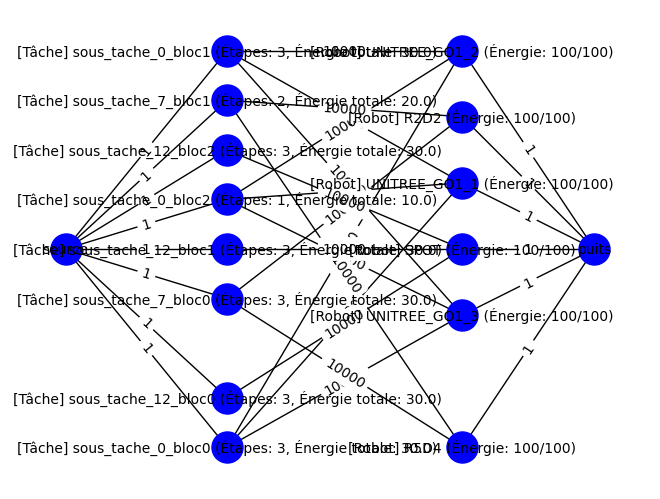

nombre de tâches : 8
nombre de robots : 6



In [155]:
# On définit une fonction qui permet de créer un graphe nx (biparti) à partir d'une liste de tâches et de robots
# (ce seront les noeuds du graphe)
# On suppose que les tâches et les robots sont des listes d'objets de type tache et robot

def create_graph(liste_taches, liste_robots):
    ''' 
    Cette fonction prend en argument une liste de tâches et une liste de robots et renvoie un graphe biparti, avec la source et le puits
    '''
    G = nx.Graph()
    # on ajoute la source et le puits
    G.add_node("source", bipartite=0)
    G.add_node("puits", bipartite=1)

    # on ajoute les tâches et les robots
    # on ajoute les tâches comme noeuds de type 0
    G.add_nodes_from(liste_taches, bipartite=0)
    # on ajoute les robots comme noeuds de type 1
    G.add_nodes_from(liste_robots, bipartite=1)

    # on ajoute les arcs entre les tâches et les robots, si le robot peut effectuer la tâche
    # on donne une capacité de 1 à chaque arc
    for t in liste_taches:
        for r in liste_robots:
            if r.meet_prerequis(tache=t):
                G.add_edge(t, r, weight=10_000)

    # on ajoute les arcs entre la source et les tâches, ainsi que les tâches et le puits
    for t in liste_taches:
        G.add_edge("source", t, weight=1)

    # on ajoute les arcs entre les robots et le puits
    for r in liste_robots:
        G.add_edge(r, "puits", weight=1)
    return G


liste_taches = liste_taches_finale

G = create_graph(liste_taches, liste_robots)

# on affiche le graphe

# on obtient les noeuds de type 0
nodes0 = {n for n, d in G.nodes(data=True) if d['bipartite'] == 0}
# on obtient les noeuds de type 1
nodes1 = {n for n, d in G.nodes(data=True) if d['bipartite'] == 1}


# Modifie la position de la source et du puits
pos = nx.bipartite_layout(G, nodes0)
pos["source"] = (-2, 0)  # Place the source node to the left of the nodes0
pos["puits"] = (2, 0)  # Place the puits node to the right of the nodes1


# Dessine le graphe, en affichant les poids des arcs
nx.draw(G, pos, with_labels=True, node_color="blue",
        node_size=500, font_size=10)


# Créé un dictionnaire des poids des arcs
edge_labels = nx.get_edge_attributes(G, 'weight')

# Dessine les poids des arcs
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

# Plot le graphe
plt.show()

print(f"nombre de tâches : {len(liste_taches)}")
print(f"nombre de robots : {len(liste_robots)}")
print("")

### Obtention de l'affectaton avec Ford-Fulkerson

In [156]:
# on applique l'algorithme de Ford Fulkerson pour trouver le flot maximal, et on en deduis les tâches affectées à chaque robot

def affectation(G):
    """ 
    Comme vu en cours, cette fonction prend en argument un graphe biparti et renvoie une affectation de tâches aux robots
    Par convention, on considère que la source est le noeud 0 et le puits le noeud 1

    Paramètres
    ----------
    G : un graphe biparti nx
    """
    # on récupère le flot maximal, ainsi que le flot
    flow_value, flow_dict = nx.maximum_flow(
        G, "source", "puits", capacity="weight")

    # on retire la source et le puits du dict flow_dict
    flow_dict.pop("source")
    flow_dict.pop("puits")

    # on récupère les tâches et les robots, on retire la source et le puits des listes
    taches = [n for n, d in G.nodes(data=True) if d['bipartite'] == 0]
    taches.remove("source")
    robots = [n for n, d in G.nodes(data=True) if d['bipartite'] == 1]
    robots.remove("puits")

    # on crée un dictionnaire qui associe à chaque tâche le robot qui lui est affecté
    affectation = {}
    for tache in taches:
        for robot in robots:
            if robot.meet_prerequis(tache) and flow_dict[tache][robot] == 1:
                affectation[tache] = robot

                print(f"Position actuelle du robot : {robot.position}")

    return affectation, flow_value


# test de la fonction affectation
affectation(G)

for robot in liste_robots:
    print(f"Position finale du Robot {robot}: {robot.position}")
# une fois l'affectation obtenue, on peut attribuer les tâches à chaque robot


def attribuer_taches(affectation):
    """ 

    Cette méthode prend en argument un dictionnaire affectation qui associe à chaque tâche le robot qui lui est affecté
    et une liste de robots modifie l'attribut tache de chaque robot
    """
    for robot in liste_robots:
        robot.clear_taches()

    for tache, robot in affectation.items():
        robot.taches.append(tache)
        robot.tache = tache


attribuer_taches(affectation(G)[0])

Position actuelle du robot : [40, 10]
Position actuelle du robot : [42, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [72, 26]
Position actuelle du robot : [70, 26]
Position actuelle du robot : [10, 26]
Position actuelle du robot : [10, 26]
Position finale du Robot [Robot] SPOT (Énergie: 100/100): [10, 26]
Position finale du Robot [Robot] UNITREE_GO1_1 (Énergie: 100/100): [38, 10]
Position finale du Robot [Robot] UNITREE_GO1_2 (Énergie: 100/100): [40, 10]
Position finale du Robot [Robot] UNITREE_GO1_3 (Énergie: 100/100): [42, 10]
Position finale du Robot [Robot] R2D2 (Énergie: 100/100): [70, 26]
Position finale du Robot [Robot] R5D4 (Énergie: 100/100): [72, 26]
Position actuelle du robot : [40, 10]
Position actuelle du robot : [42, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [72, 26]
Position actuelle du robot : [70, 26]
Position actuelle du robot : [10, 26]
P

### Affichage de l'affectation

In [157]:
def afficher_affectation1(affectation):
    """ 
    Cette fonction prend en argument un dictionnaire affectation qui associe à chaque tâche le robot qui lui est affecté
    et renvoie un dataframe pandas qui représente l'affectation
    """
    d = {"Tâches": [], "Robots": []}
    for tache, robot in affectation.items():
        d["Tâches"].append(tache.nom)
        d["Robots"].append(robot.nom)
    return pd.DataFrame(d)


afficher_affectation1(affectation(G)[0])

Position actuelle du robot : [40, 10]
Position actuelle du robot : [42, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [72, 26]
Position actuelle du robot : [70, 26]
Position actuelle du robot : [10, 26]
Position actuelle du robot : [10, 26]


,Tâches,Robots
0,sous_tache_0_bloc0,UNITREE_GO1_3
1,sous_tache_0_bloc1,UNITREE_GO1_1
2,sous_tache_0_bloc2,UNITREE_GO1_1
3,sous_tache_7_bloc0,R5D4
4,sous_tache_7_bloc1,R2D2
5,sous_tache_12_bloc0,SPOT
6,sous_tache_12_bloc1,SPOT


### Affichage du bilan énergétique correspondant à l'affectation trouvée

In [158]:
import pandas as pd

# Charger le fichier Excel
df = pd.read_excel("../data/robots_taches.xlsx", header=0, sheet_name="taches")  # Remplacez par le nom de votre fichier

# Accéder à la colonne "Énergies"
energies = df["energies"].tolist()  # Ou df.iloc[:, 4] si la colonne est en position 5 (index 4)

print("Liste des énergies :", energies)

Liste des énergies : [10, 10, 10, 10, 10, 10, 10, 20, 20, 20, 20, 20, 15, 15, 15, 15, 15, 15, 15, 15, 15]


In [164]:
def lire_energies_excel():
    """Charge les énergies depuis le fichier Excel en utilisant la clé 'sous_tache'"""
    try:
        df = pd.read_excel("../data/robots_taches.xlsx", header=0, sheet_name="taches")
        # Crée un dict sous_tache -> energies
        return {row['sous_tache']: row['energies'] for _, row in df.iterrows()}
    except Exception as e:
        raise ValueError(f"Erreur lecture fichier Excel: {str(e)}")

def calculer_energie_restante():
    """
    Calcule l'énergie restante réelle pour chaque robot
    en utilisant la clé 'sous_tache' pour récupérer l'énergie
    """
    try:
        energies_excel = lire_energies_excel()
    except Exception as e:
        print(f"ERREUR: {str(e)}")
        return pd.DataFrame()

    affectation_actuelle, _ = affectation(G)
    
    bilan = []
    for robot, taches in [(r, [t for t, rob in affectation_actuelle.items() if rob == r]) 
                         for r in set(affectation_actuelle.values())]:
        
        energie_consommee = 0
        for tache in taches:
            # Ici on suppose que tache.nom correspond à une valeur de la colonne 'sous_tache'
            energie_consommee += energies_excel.get(tache.nom, 0)
        
        energie_restante = robot.energie_restante - energie_consommee
        
        energie_restante = max(0, energie_restante)
        
        if energie_restante < (robot.energie_max * 0.3):
            print(f"-> Recharge automatique de {robot.nom}...")
            energie_restante = robot.energie_max
        
        bilan.append({
            'Robot': robot.nom,
            'Type': robot.fonction,
            'Énergie Initiale': robot.energie_restante,
            'Énergie Consommée': energie_consommee,
            'Énergie Restante': energie_restante,
            'Recharge Nécessaire': 'OUI' if energie_restante < (robot.energie_max * 0.3) else 'NON'
        })
    
    return pd.DataFrame(bilan)

# --------------------------------------------------
# UTILISATION
# --------------------------------------------------
try:
    # Affichage des résultats
    print("\n=== ÉNERGIE RESTANTE PAR ROBOT ===")
    df_energie = calculer_energie_restante()
    
    # Version simplifiée
    print(df_energie[['Robot', 'Énergie Restante', 'Recharge Nécessaire']].to_string(index=False))
    
    # Version détaillée
    print("\n=== DÉTAILS COMPLETS ===")
    print(df_energie.to_string(index=False))

except Exception as e:
    print(f"ERREUR: {str(e)}")
    print("Vérifications nécessaires:")
    print("- Le fichier robots_taches.xlsx existe avec la feuille 'taches'")
    print("- La feuille contient les colonnes 'sous_tache' et 'energies'")
    print("- Les tâches ont bien l'attribut 'nom' correspondant à 'sous_tache' dans Excel")



=== ÉNERGIE RESTANTE PAR ROBOT ===
Position actuelle du robot : [40, 10]
Position actuelle du robot : [42, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [72, 26]
Position actuelle du robot : [70, 26]
Position actuelle du robot : [10, 26]
Position actuelle du robot : [10, 26]
        Robot  Énergie Restante Recharge Nécessaire
         R5D4                80                 NON
UNITREE_GO1_3                90                 NON
         R2D2                80                 NON
UNITREE_GO1_1                80                 NON
         SPOT                70                 NON

=== DÉTAILS COMPLETS ===
        Robot        Type  Énergie Initiale  Énergie Consommée  Énergie Restante Recharge Nécessaire
         R5D4 Thermometre               100                 20                80                 NON
UNITREE_GO1_3      Camera               100                 10                90                 NON
         R2D2 Therm

In [248]:
def conflit(liste_robots):
    """ 
    Fonction qui renvoie True s'il y a un conflit entre les robots, 
    c'est à dire si ils sont sur le même lieu à la même étape
    """
    lieux = []
    for robot in liste_robots:
        if robot.taches:
            lieux.append(robot.taches[0].get_lieu(robot.current_tache))
    return len(lieux) != len(set(lieux))


def assigner_position(room, k=1):
    """
    Methode qui assigne aux robots le chemin qu'ils vont parcourir dans la pièce dynamique 
    En particulier les velurs sont misent à l'échele de la grille
    paramètres:
    room: objet de la classe Piece
    k: facteur d'agrandissement de la grille

    """
    for robot in room.liste_robot:
        position = []
        lieu_depart = robot.position
        lieu_depart = [lieu_depart[0], lieu_depart[1]]

        print(f"[{robot.nom}] lieu départ : {lieu_depart}")

        pathes, _ = room.plus_court_chemin_tsp(
            lieu_depart, grid_size=2, robot=robot, k=1)

        for l in pathes:
            for coord in l:
                x, y = coord
                coord = (x*k, y*k)
                position.append(coord)
        robot.position = position

Position de r5d4: [72, 26]
Position de Unitree_go1: [38, 10]
Position de SPOT: [10, 26]
[UNITREE_GO1_1] lieu départ : [38, 10]
[R5D4] lieu départ : [72, 26]
[SPOT] lieu départ : [10, 26]


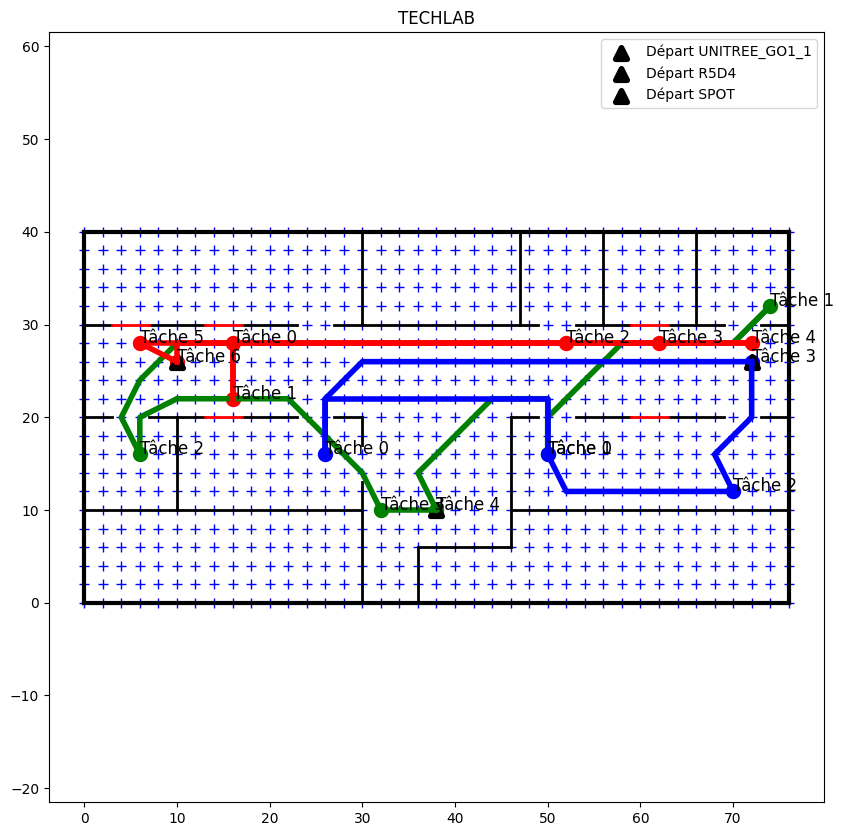

In [249]:
# on créé la pièce
largeur, longueur = 40, 76
room3 = Piece(longueur, largeur, liste_murs, liste_portes)

# on créé les robots
Unitree_go1 = liste_robots[1]
SPOT = liste_robots[0]
r5d4 = liste_robots[-1]

# Debug: verificar posições
print(f"Position de r5d4: {r5d4.position}")
print(f"Position de Unitree_go1: {Unitree_go1.position}")
print(f"Position de SPOT: {SPOT.position}")

# on associe les robots à la pièce
room3.associer_robot(Unitree_go1)
room3.associer_robot(r5d4)
room3.associer_robot(SPOT)
# on assigne leur chemin aux robots
assigner_position(room3)

room3.afficher(plot_grille=True, grid_size=2,
               plot_accessible=False, plot_path=True)

# Exemple 

L'idée TSP

In [156]:
Unitree_go1.reset_position()
SPOT.reset_position()
r5d4.reset_position()

scale = lambda x: [coord / 10 for coord in x]

Unitree_go1.position = scale(Unitree_go1.position)
SPOT.position = scale(SPOT.position)
r5d4.position = scale(r5d4.position)

Avant reset: [(380.0, 100.0), (360, 140), (400, 180), (440, 220), (500, 220), (500, 160), (500, 160), (500, 200), (540, 240), (580, 280), (640, 280), (700, 280), (740, 320), (740, 320), (700, 280), (640, 280), (580, 280), (520, 280), (460, 280), (400, 280), (340, 280), (280, 280), (220, 280), (160, 280), (100, 280), (60, 240), (40, 200), (60, 160), (60, 160), (60, 200), (100, 220), (160, 220), (220, 220), (260, 180), (300, 140), (320, 100), (320, 100), (380, 100)]
Après reset: [380.0, 100.0]
Avant reset: [(520, 280), (560, 280), (620, 280), (620, 280), (660, 280), (720, 280), (720, 280), (720, 220), (720, 220), (660, 220), (620, 220), (620, 220), (560, 220), (520, 220), (520, 220), (520, 280), (520, 280)]
Après reset: [520, 280]
Avant reset: [(720.0, 260.0), (660, 260), (600, 260), (540, 260), (480, 260), (420, 260), (360, 260), (300, 260), (260, 220), (260, 160), (260, 160), (260, 220), (320, 220), (380, 220), (440, 220), (500, 220), (500, 160), (500, 160), (520, 120), (580, 120), (64